# When can machine learning beat a fixed rule? Simulation and JPMaQS evidence

Di Liu · companion to the Macrosynergy example-code study

The example-code study found that learned signals did not beat a simple theory-signed composite. This notebook
asks **when** they could, in two parts:

* **Part A: simulation with known truth.** Six ways the truth can depart from the rule's assumptions, four panel
  sizes and three signal strengths, giving a "phase diagram" of where each learner wins.
* **Part B: real data, pre-registered.** Duration, FX and equity returns across 16–24 markets (JPMaQS, Kaggle
  release), four learners against theory-signed rules, judged by criteria fixed before the run.

Runtime: Part A about 7 minutes on 2 cores (set `N_SEEDS = 2` for a quick run); Part B about 3 minutes.
Data: JPMaQS CSV(s) in `./data`, otherwise downloaded from Kaggle with `kagglehub`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from joblib import Parallel, delayed

from macrosynergy.panel import make_zn_scores, linear_composite
from macrosynergy.signal import SignalReturnRelations
from macrosynergy.learning import SignalOptimizer, ExpandingKFoldPanelSplit
from macrosynergy.pnl import NaivePnL
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import make_scorer

plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.width", 200)
sharpe = lambda x: x.mean() / x.std() * np.sqrt(252)

N_SEEDS = 6          # simulated panels per cell in Part A (6 = as reported; 2 = quick run)

def load_jpmaqs(data_dir=Path("data")):
    """JPMaQS-format CSVs from ./data, else the Kaggle dataset via kagglehub."""
    files = sorted(data_dir.glob("*.csv")) if data_dir.exists() else []
    if not files:
        import kagglehub
        path = Path(kagglehub.dataset_download("macrosynergy/fixed-income-returns-and-macro-trends"))
        files = sorted(path.rglob("*.csv"))
    frames = []
    for f in files:
        raw = pd.read_csv(f)
        if {"real_date", "cid", "xcat", "value"} <= set(raw.columns):
            frames.append(raw[["real_date", "cid", "xcat", "value"]])
    out = pd.concat(frames, ignore_index=True)
    out["real_date"] = pd.to_datetime(out["real_date"])
    return out

dfd = load_jpmaqs()
print(f"{len(dfd):,} rows · {dfd['cid'].nunique()} markets · {dfd['xcat'].nunique()} categories · "
      f"{dfd['real_date'].min().date()} → {dfd['real_date'].max().date()}")

3,390,059 rows · 24 markets · 25 categories · 2000-01-03 → 2023-12-14


## Part A · Simulation with known truth: when should a learner beat a fixed rule?

On real data we never know the true relationship, so a learner that loses to a rule leaves an open question:
was there nothing to learn, or not enough data to learn it? Part A answers that by simulating panels where the
truth is known, and varying exactly the conditions that should favour learning.

**The panel.** N markets × T months. Seven macro features (thirty in one scenario) are persistent AR(1) series
(monthly φ = 0.9) sharing a common factor, like real macro indicators. Next-month returns are a true signal
plus noise; the noise level sets the best attainable monthly R² (0.5%, 2% or 8%; real macro signals sit around
1–3%). "Theory" says every feature has a positive effect, which is true *on average* in every scenario.

**Six scenarios**, from the rule's home ground to settings built to favour learning:

| Scenario | Truth |
|---|---|
| Rule exactly right | equal weights, linear, the same in every market |
| Thresholds | each feature matters only beyond \|x\| > 1 |
| Unequal weights (7) | correct signs, but weights 3 : 2 : 1 : 0.5 and three irrelevant features |
| Unequal weights (30) | thirty features, only six relevant, unequal weights |
| Opposite signs by country | for 3 of 7 features the sign is + in half the markets and − in the other half (e.g. oil for exporters vs importers); an observable country type is available |
| Regime-dependent sign | for 3 of 7 features the effect is strong in a "high" regime and reversed in a "low" one; the regime is observable |

**Panel sizes.** 4 markets × 15 years (like the example-code panel), 10 × 20, 24 × 25 (like the full Kaggle
panel) and a hypothetical 48 × 40.

**Contenders**, all refitted every 12 months on an expanding window and evaluated strictly out of sample:
* **Rule**: equal-weight average of the theory-signed features (no estimation).
* **Sign-constrained**: non-negative least squares on the theory-signed features.
* **Ridge (free signs)**: all features plus the observable context (country type, regime); α chosen on a time-ordered hold-out.
* **Linear + interactions**: as Ridge, plus every feature × country type and feature × regime, i.e. a learner *told* which interactions might exist.
* **Gradient boosting**: all features plus context; it must *discover* thresholds and interactions itself.

**Metric.** Out-of-sample information coefficient (IC): the pooled correlation of predictions with realised
returns. The "oracle" (the true signal) gives the best IC attainable.

In [2]:
# ---- Part A: simulator and walk-forward contest ----------------------------
SCENARIOS = {
    "linear":     "Equal weights, linear, same in every market (the rule is exactly right)",
    "sparse":     "Linear, correct signs, but unequal weights and some irrelevant features",
    "many":       "30 features, correct signs, only 6 relevant with unequal weights",
    "threshold":  "Features matter only beyond a threshold (|x| > 1)",
    "hetero":     "For 3 of 7 features the sign is opposite in half the markets (e.g. oil for exporters vs importers)",
    "regime":     "For 3 of 7 features the effect is strong in a high regime and reversed in a low one (observable state)",
}


def simulate(scenario, N, T, r2, seed):
    rng = np.random.default_rng(seed)
    K = 30 if scenario == "many" else 7
    # persistent features with a common factor (monthly AR(1), phi = 0.9)
    common = np.zeros(T)
    X = np.zeros((N, T, K))
    for t in range(1, T):
        common[t] = 0.9 * common[t - 1] + rng.normal(0, np.sqrt(1 - 0.81))
        X[:, t, :] = 0.9 * X[:, t - 1, :] + rng.normal(0, np.sqrt(1 - 0.81), (N, K))
    X = np.sqrt(0.7) * X + np.sqrt(0.3) * common[None, :, None]
    ctype = np.where(np.arange(N) < N // 2, 1.0, -1.0)           # static country type (+1 / -1)
    regime = np.zeros(T)                                            # slow observable state, mostly < 0
    for t in range(1, T):
        regime[t] = 0.97 * regime[t - 1] + rng.normal(0, np.sqrt(1 - 0.97 ** 2))
    regime = regime - 0.5                                           # high regime ~ 30% of the time
    R = np.broadcast_to(regime[None, :], (N, T))
    if scenario == "linear":
        f = X.mean(axis=2)
    elif scenario == "sparse":
        w = np.array([3, 2, 1, 0.5, 0, 0, 0], float); f = X @ (w / w.sum())
    elif scenario == "many":
        w = np.zeros(K); w[:6] = [3, 2, 1.5, 1, 0.5, 0.5]; f = X @ (w / w.sum())
    elif scenario == "threshold":
        f = (X - np.clip(X, -1, 1)).mean(axis=2)
    elif scenario == "hetero":
        sgn = np.ones((N, K)); sgn[:, :3] = np.where(ctype[:, None] > 0, 1.0, -1.0)   # opposite signs: average effect 0
        f = (X * sgn[:, None, :]).mean(axis=2)
    elif scenario == "regime":
        g = np.where(R > 0, 2.0, -0.5)[..., None]                   # strong in the high regime, reversed in the low one
        f = (np.concatenate([X[..., :3] * g, X[..., 3:]], axis=2)).mean(axis=2)
    f = (f - f.mean()) / f.std()
    beta = np.sqrt(r2 / (1 - r2))
    y = np.full((N, T), np.nan)
    y[:, :-1] = beta * f[:, :-1] + rng.normal(0, 1, (N, T - 1))     # y[:, t] = return over t -> t+1 (target for X at t)
    aux = np.stack([np.broadcast_to(ctype[:, None], (N, T)), R], axis=2)   # observable context: country type, regime
    return X, aux, y, f


def walk_forward(X, aux, y, f, first=60, step=12):
    """Expanding-window walk-forward; refit every `step` months. Returns OOS ICs by method."""
    N, T, K = X.shape
    preds = {m: [] for m in ["RULE", "RIDGE", "SIGNED", "LIN_INT", "GB", "ORACLE"]}
    ys = []
    full = np.concatenate([X, aux], axis=2)                          # ML sees context variables too
    inter = np.concatenate([X, X * aux[..., :1], X * aux[..., 1:2], aux], axis=2)   # linear with interactions
    for s in range(first, T - 1, step):
        e = min(s + step, T - 1)
        tr = (slice(None), slice(0, s))
        te = (slice(None), slice(s, e))
        ytr = y[tr].ravel()
        flat = lambda A, sl: A[sl].reshape(-1, A.shape[2])
        # RULE: equal-weight average of the theory-oriented features (no estimation)
        preds["RULE"].append(X[te].mean(axis=2).ravel())
        preds["ORACLE"].append(f[te].ravel())
        # Ridge with alpha chosen on the last 20% of the training window (time-ordered holdout)
        cut = int(s * 0.8)
        def pick_alpha(A):
            best, best_mse = None, np.inf
            for a in (1.0, 10.0, 100.0, 1000.0):
                m = Ridge(alpha=a, fit_intercept=False).fit(A[:, :cut].reshape(-1, A.shape[2]), y[:, :cut].ravel())
                mse = np.mean((m.predict(A[:, cut:s].reshape(-1, A.shape[2])) - y[:, cut:s].ravel()) ** 2)
                if mse < best_mse:
                    best, best_mse = a, mse
            return best
        a = pick_alpha(full)
        preds["RIDGE"].append(Ridge(alpha=a, fit_intercept=False).fit(flat(full, tr), ytr).predict(flat(full, te)))
        preds["SIGNED"].append(LinearRegression(fit_intercept=False, positive=True).fit(flat(X, tr), ytr).predict(flat(X, te)))
        a = pick_alpha(inter)
        preds["LIN_INT"].append(Ridge(alpha=a, fit_intercept=False).fit(flat(inter, tr), ytr).predict(flat(inter, te)))
        gb = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150,
                                           min_samples_leaf=50, random_state=0)
        preds["GB"].append(gb.fit(flat(full, tr), ytr).predict(flat(full, te)))
        ys.append(y[te].ravel())
    yy = np.concatenate(ys)
    ic = {m: np.corrcoef(np.concatenate(p), yy)[0, 1] for m, p in preds.items()}
    return ic


def run_one(scenario, N, T, r2, seed):
    X, aux, y, f = simulate(scenario, N, T, r2, seed)
    ic = walk_forward(X, aux, y, f)
    return {"scenario": scenario, "N": N, "T": T, "r2": r2, "seed": seed, **ic}

In [3]:
# ---- Part A: run the grid -------------------------------------------------
SIZES = [(4, 180), (10, 240), (24, 300), (48, 480)]   # markets x months
R2S = [0.005, 0.02, 0.08]                              # attainable monthly R^2
jobs = [(sc, N, T, r2, s) for sc in SCENARIOS for (N, T) in SIZES for r2 in R2S for s in range(N_SEEDS)]
simres = pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_one)(*j) for j in jobs))
simres.to_csv("sim_results.csv", index=False)
print(f"{len(simres)} simulated panels")
# average IC by scenario at the panel size closest to the real data (24 markets, R^2 2%)
display(simres.query("N == 24 and r2 == 0.02").groupby("scenario")[["ORACLE", "RULE", "SIGNED", "RIDGE", "LIN_INT", "GB"]].mean().round(3))

432 simulated panels


,ORACLE,RULE,SIGNED,RIDGE,LIN_INT,GB
scenario,,,,,,
hetero,0.149,0.108,0.108,0.106,0.131,0.084
linear,0.147,0.147,0.138,0.138,0.130,0.103
many,0.142,0.114,0.133,0.123,0.104,0.090
regime,0.141,0.106,0.105,0.102,0.108,0.081
sparse,0.150,0.125,0.144,0.138,0.127,0.105
threshold,0.146,0.132,0.124,0.123,0.114,0.095


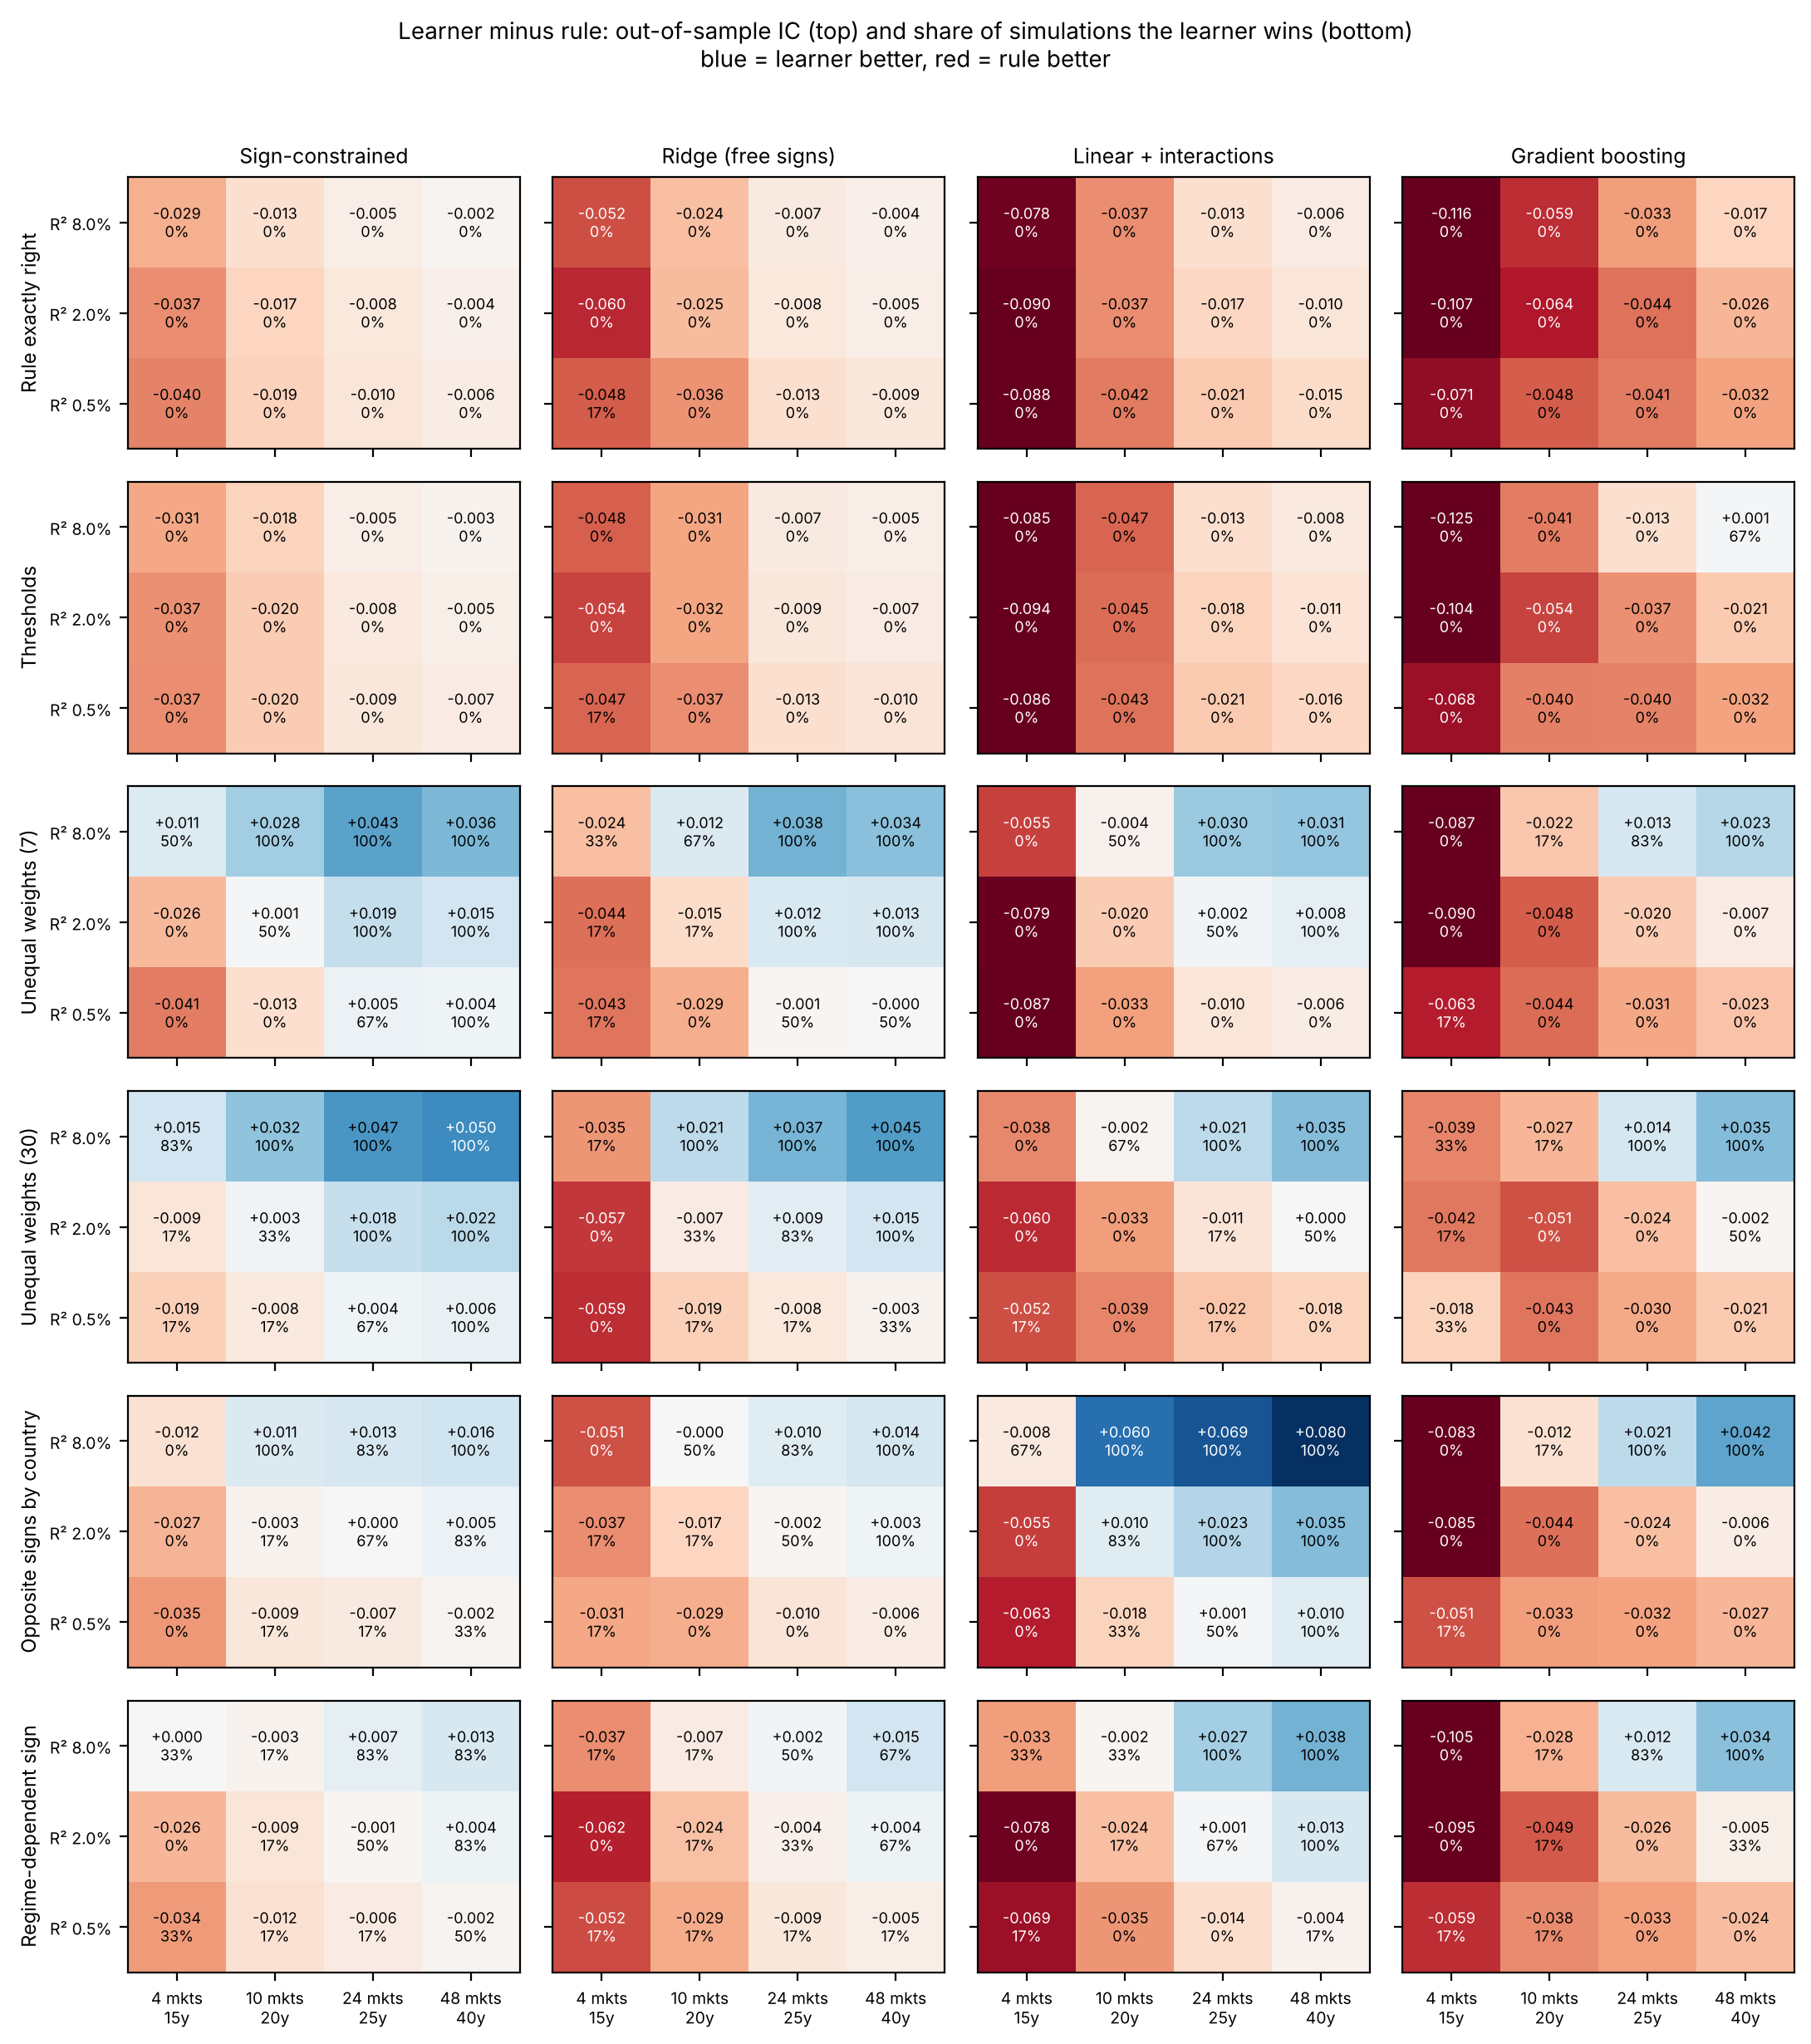

In [4]:
# ---- Part A: phase diagram -------------------------------------------------
def phase_diagram(df, path=None):
    """Mean out-of-sample IC of each learner minus the rule's, by scenario, panel size and signal strength."""
    M = {"SIGNED": "Sign-constrained", "RIDGE": "Ridge (free signs)", "LIN_INT": "Linear + interactions", "GB": "Gradient boosting"}
    SC = {"linear": "Rule exactly right", "threshold": "Thresholds", "sparse": "Unequal weights (7)",
          "many": "Unequal weights (30)", "hetero": "Opposite signs by country", "regime": "Regime-dependent sign"}
    sizes = ["4x180", "10x240", "24x300", "48x480"]
    df = df.copy(); df["size"] = df["N"].astype(str) + "x" + df["T"].astype(str)
    fig, axes = plt.subplots(len(SC), len(M), figsize=(11, 12.5), sharex=True, sharey=True)
    norm = TwoSlopeNorm(vmin=-0.08, vcenter=0.0, vmax=0.08)
    for i, (sc, sl) in enumerate(SC.items()):
        for j, (m, ml) in enumerate(M.items()):
            g = df[df["scenario"] == sc].assign(d=lambda x: x[m] - x["RULE"])
            piv = g.groupby(["r2", "size"])["d"].mean().unstack()[sizes].sort_index(ascending=False)
            win = g.groupby(["r2", "size"])["d"].apply(lambda x: (x > 0).mean()).unstack()[sizes].sort_index(ascending=False)
            ax = axes[i, j]
            ax.imshow(piv.values, cmap="RdBu", norm=norm, aspect="auto")
            for a in range(piv.shape[0]):
                for b in range(piv.shape[1]):
                    v, wv = piv.values[a, b], win.values[a, b]
                    ax.text(b, a, f"{v:+.3f}\n{wv:.0%}", ha="center", va="center", fontsize=6.5,
                            color="white" if abs(v) > 0.05 else "black")
            ax.set_xticks(range(4)); ax.set_xticklabels(["4 mkts\n15y", "10 mkts\n20y", "24 mkts\n25y", "48 mkts\n40y"], fontsize=7)
            ax.set_yticks(range(3)); ax.set_yticklabels([f"R² {r:.1%}" for r in piv.index], fontsize=7)
            if i == 0: ax.set_title(ml, fontsize=9)
            if j == 0: ax.set_ylabel(sl, fontsize=8.5)
    fig.suptitle("Learner minus rule: out-of-sample IC (top) and share of simulations the learner wins (bottom)\n"
                 "blue = learner better, red = rule better", fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if path: plt.savefig(path, dpi=150)
    return fig

phase_diagram(simres, "phase.png"); plt.show()

### Part A · Findings: where each approach wins

Each cell compares a learner's out-of-sample information coefficient (IC: correlation of its prediction with
next-month returns) with the rule's, averaged over six simulated panels per cell, together with the share of
panels the learner wins. For orientation, the real JPMaQS panels in Part B (16–24 markets, roughly 17 years of
monthly data, ICs around 0.1–0.2) sit near the **24-market, R² 2%** cells.

1. **When the rule's assumptions hold, learners never win on average.** In "rule exactly right" every learner is
   behind the rule in every cell, winning at most one simulation in six. Estimation costs shrink with more data
   but never turn positive: a learner can at best rediscover equal weights, with noise.
2. **Thresholds alone are not a reason for ML.** A linear rule captures most of a threshold effect (the rule's IC
   is 0.13 against an oracle of 0.15 at 24 markets, R² 2%). Gradient boosting draws level only at 48 markets with
   R² 8%.
3. **Unequal weights are where learning first pays.** With relevant and irrelevant inputs mixed, the
   sign-constrained learner beats the rule in 100% of simulations from 24 markets at R² 2% (+0.019 IC with seven
   inputs, +0.018 with thirty). With 4 markets it loses unless the signal is very strong (R² 8%).
4. **Opposite signs across countries need structure, not flexibility.** Linear regression with an interaction term
   it was told to include beats the rule in 100% of simulations from 24 markets at R² 2% (+0.023 IC), and by
   +0.06–0.08 at R² 8%. Gradient boosting, which has to discover the interaction itself, still loses at R² 2% even
   with 48 markets and 40 years.
5. **Regime-dependent signs:** the same pattern, weaker. The interaction model wins from 24 markets at R² 8%, or
   48 markets at R² 2%.
6. **Small panels favour the rule everywhere.** With 4 markets and 15 years, learners lose in essentially every
   scenario, which matches the four-market result in the example-code notebook.
7. **Gradient boosting is the weakest learner throughout.** It needs the largest panels and the strongest signals
   before it competes, because it spends data discovering structure that a well-specified model is given.

**What this predicts for Part B.** At real-data scale, learning can only beat a theory-signed rule if the rule
mis-weights its inputs or misses sign heterogeneity, and then only by about 0.02 in IC. That is a small edge
relative to sampling noise over 17 years, so a statistically significant win on real data would be surprising.

## Part B · Pre-registration: machine learning vs fixed rules across duration, FX and equity

*Written before any Part B result was computed. Nothing below was changed after the results were seen.*

**Question.** Part A shows, with known truth, when a learner should beat a theory-signed rule: when signs
are unknown or heterogeneous, when effects depend on a regime, and when there is enough data relative to
the noise. FX and equity returns are where economic theory is least sure about signs, so if machine learning
beats fixed rules anywhere in this dataset, it should be there.

**Data.** Kaggle JPMaQS (version 17), point-in-time, 2000–2023.

| Asset class | Target return | Markets | Excluded periods |
|---|---|---|---|
| Duration | `DU05YXR_VT10` (5y swap receiver) | 24 | untradable (`FXUNTRADABLE_NSA`) |
| FX | `FXXR_VT10` (long local currency vs its benchmark currency) | 23 (no USD) | untradable and FX-targeted (`FXTARGETED_NSA`: CHF floor, CZK floor, INR) |
| Equity | `EQXR_VT10` (long local equity index) | 16 | untradable |

**Features (nine, identical for every asset class).** All are sequential, point-in-time z-scores around zero
(mean-absolute-deviation scale, half panel / half own-market, winsorised at ±3):

| Code | Definition |
|---|---|
| `XCPIC` | core CPI 6m/6m annualised − effective inflation target |
| `XCPIH` | headline CPI %oya − effective inflation target |
| `XGDP` | GDP growth nowcast − its 5-year median (`INTRGDPv5Y_NSA_P1M1ML12_3MMA`) |
| `XPCG` | private credit growth − (5-year real GDP growth + inflation target) |
| `DPCGDP` | 1-year change in private credit / GDP |
| `RYLD5` | real 5-year swap yield |
| `RYLD2` | real 2-year swap yield |
| `RSLOPE` | real 5y − real 2y swap yield |
| `FXCRR` | FX carry (interest differential, annualised) |

**Fixed rules (theory signs; 0 = sign not clear from theory, so excluded).**

| Feature | Duration (receive) | FX (long local currency) | Equity (long) |
|---|---|---|---|
| `XCPIC`, `XCPIH` | − | 0 | − |
| `XGDP` | − | + | + |
| `XPCG`, `DPCGDP` | − | 0 | 0 |
| `RYLD5` | + | 0 | − |
| `RYLD2` | + | + | − |
| `RSLOPE` | + | 0 | 0 |
| `FXCRR` | 0 | + | 0 |

Each rule is the equal-weighted average of its signed features: 8 features for duration, 3 for FX, 5 for equity.

**Learners.** All are re-selected quarterly by `SignalOptimizer` with 4-fold expanding panel cross-validation,
scored by the package's panel significance probability, with no intercept:
1. `SIGNED`: non-negative least squares / non-negative Ridge on the rule's signed features (the rule with learned weights).
2. `RIDGE`: Ridge on all nine features, signs free.
3. `LIN_INT`: Ridge on all nine features plus their interactions with an emerging-market indicator and a high-inflation indicator (headline inflation more than 2 percentage points above target), signs free.
4. `GB`: gradient boosting on all nine features plus the two context variables (can learn thresholds and interactions).

**Evaluation.** January 2007 – December 2023 (17 years; every candidate trading), monthly signals, next-month
returns, naive PnL with monthly rebalancing, one-day slippage, 10% vol scaling, gross of costs.

**Tests and decision rule.** 12 learner-vs-rule comparisons (4 learners × 3 asset classes) plus 4 multi-asset
portfolio comparisons (each learner's three asset-class PnLs averaged vs the three rules averaged) = 16 tests.
A learner **beats the rule** only if:
* its paired HAC t-statistic against the rule is ≥ 2.96 (Bonferroni-adjusted 5% two-sided for 16 tests), **and**
* its PnL gap against the rule is positive in **both** the developed-market and emerging-market sub-panels.

Every candidate is also reported on the predictive criteria used before (pooled Pearson positive with
p < 0.05; positive in at least two thirds of markets; Sharpe positive excluding 2022).

**Expectations (stated before running).**
1. Duration: the rule is at least as good as every learner (as in the example-code notebook).
2. FX: the best chance for machine learning, because three of the rule's exclusions are sign-ambiguous rather than irrelevant. I expect the learners to come closest here, but not to pass the Bonferroni bar.
3. Equity: low predictability for every candidate; equity returns are the noisiest.
4. No learner beats the rule under the decision rule. Part A predicts that the real data are too short and noisy relative to the size of any nonlinearity.

In [5]:
# ---- CELL B1: features, context variables and blacklists ---------------------
from macrosynergy.panel import make_blacklist
from macrosynergy.learning import panel_significance_probability
import statsmodels.api as sm

DMC = ["AUD", "CAD", "CHF", "EUR", "GBP", "JPY", "NOK", "NZD", "SEK", "USD"]
EMC = ["CLP", "COP", "CZK", "HUF", "IDR", "ILS", "INR", "KRW", "MXN", "PLN", "THB", "TRY", "TWD", "ZAR"]
ASSETS = {
    "Duration": {"ret": "DU05YXR_VT10", "cids": DMC + EMC},
    "FX":       {"ret": "FXXR_VT10",    "cids": [c for c in DMC + EMC if c != "USD"]},
    "Equity":   {"ret": "EQXR_VT10",    "cids": ["AUD", "CAD", "CHF", "EUR", "GBP", "JPY", "SEK", "USD",
                                                 "INR", "KRW", "MXN", "PLN", "THB", "TRY", "TWD", "ZAR"]},
}
FEATS9 = ["XCPIC", "XCPIH", "XGDP", "XPCG", "DPCGDP", "RYLD5", "RYLD2", "RSLOPE", "FXCRR"]
SIGNS = {   # theory signs; 0 = not clear from theory, excluded from the rule
    "Duration": {"XCPIC": -1, "XCPIH": -1, "XGDP": -1, "XPCG": -1, "DPCGDP": -1, "RYLD5": 1, "RYLD2": 1, "RSLOPE": 1, "FXCRR": 0},
    "FX":       {"XCPIC": 0, "XCPIH": 0, "XGDP": 1, "XPCG": 0, "DPCGDP": 0, "RYLD5": 0, "RYLD2": 1, "RSLOPE": 0, "FXCRR": 1},
    "Equity":   {"XCPIC": -1, "XCPIH": -1, "XGDP": 1, "XPCG": 0, "DPCGDP": 0, "RYLD5": -1, "RYLD2": -1, "RSLOPE": 0, "FXCRR": 0},
}
EVAL_START_B = "2007-01-01"

def wide_(df, xc, cids):
    return df[(df["xcat"] == xc) & (df["cid"].isin(cids))].pivot(index="real_date", columns="cid", values="value").sort_index()

def long_(w, xc):
    s = w.stack(); s.index = s.index.set_names(["real_date", "cid"])
    o = s.rename("value").reset_index(); o["xcat"] = xc
    return o[["real_date", "cid", "xcat", "value"]]

def merge_bl(*bls):
    out = {}
    for bl in bls:
        for k, v in (bl or {}).items():
            key, i = k, 1
            while key in out:
                i += 1; key = f"{k.split('_')[0]}_x{i}"
            out[key] = v
    return out

def build_asset_panel(asset):
    cfg = ASSETS[asset]; cids = cfg["cids"]
    bl = make_blacklist(dfd, xcat="FXUNTRADABLE_NSA", cids=[c for c in cids if c != "USD"])
    if asset == "FX":
        bl = merge_bl(bl, make_blacklist(dfd, xcat="FXTARGETED_NSA", cids=cids))
    w = lambda xc: wide_(dfd, xc, cids)
    raw = {"XCPIC": w("CPIC_SJA_P6M6ML6AR") - w("INFTEFF_NSA"),
           "XCPIH": w("CPIH_SA_P1M1ML12") - w("INFTEFF_NSA"),
           "XGDP": w("INTRGDPv5Y_NSA_P1M1ML12_3MMA"),
           "XPCG": w("PCREDITBN_SJA_P1M1ML12") - w("RGDP_SA_P1Q1QL4_20QMA") - w("INFTEFF_NSA"),
           "DPCGDP": w("PCREDITGDP_SJA_D1M1ML12"),
           "RYLD5": w("RYLDIRS05Y_NSA"), "RYLD2": w("RYLDIRS02Y_NSA"),
           "RSLOPE": w("RYLDIRS05Y_NSA") - w("RYLDIRS02Y_NSA"),
           "FXCRR": w("FXCRR_NSA")}
    # USD is the base currency, so its FX carry against itself is zero by definition (no series is published)
    if "USD" in cids:
        raw["FXCRR"]["USD"] = raw["FXCRR"].drop(columns="USD", errors="ignore").notna().any(axis=1).map({True: 0.0, False: np.nan})
    d = pd.concat([dfd[dfd["cid"].isin(cids) & (dfd["xcat"] == cfg["ret"])][["real_date", "cid", "xcat", "value"]]]
                  + [long_(v, k) for k, v in raw.items()], ignore_index=True)
    for xc in FEATS9:
        if d.loc[d["xcat"] == xc, "cid"].nunique() == 0:
            continue
        d = pd.concat([d, make_zn_scores(d, xcat=xc, cids=cids, sequential=True, iis=False, min_obs=261 * 2,
                                         neutral="zero", est_freq="m", thresh=3.0, pan_weight=0.5,
                                         blacklist=bl, postfix="_ZN")], ignore_index=True)
    if "USD" in cids:   # zero carry has a zero z-score whatever the scale (its own scale is 0, so the package drops it)
        base = d[(d["cid"] == "USD") & (d["xcat"] == "XCPIC_ZN")][["real_date", "cid"]]
        d = pd.concat([d, base.assign(xcat="FXCRR_ZN", value=0.0)], ignore_index=True)
    zf = [f + "_ZN" for f in FEATS9 if (d["xcat"] == f + "_ZN").any()]
    # context variables: emerging-market indicator and high-inflation regime (headline > target + 2pp)
    hiinf = (raw["XCPIH"] > 2).astype(float).where(raw["XCPIH"].notna())
    em = pd.DataFrame({c: float(c in EMC) for c in cids}, index=hiinf.index)
    d = pd.concat([d, long_(em, "EMDUM"), long_(hiinf, "HIINF")], ignore_index=True)
    inter = []
    for z in zf:
        zw = wide_(d, z, cids)
        inter += [long_(zw * em.reindex(zw.index), z + "xEM"), long_(zw * hiinf.reindex(zw.index), z + "xHI")]
    d = pd.concat([d] + inter, ignore_index=True)
    sgn = SIGNS[asset]
    rule_feats = [f + "_ZN" for f in FEATS9 if sgn[f] != 0 and f + "_ZN" in zf]
    d = pd.concat([d, linear_composite(d, xcats=rule_feats, cids=cids, signs=[sgn[f.replace("_ZN", "")] for f in rule_feats],
                                       complete_xcats=False, new_xcat="RULE")], ignore_index=True)
    # signed (theory-oriented) copies for the sign-constrained learner
    for f in rule_feats:
        d = pd.concat([d, long_(wide_(d, f, cids) * sgn[f.replace("_ZN", "")], f + "_S")], ignore_index=True)
    return d, bl, zf, rule_feats

panels_B = {}
for asset in ASSETS:
    panels_B[asset] = build_asset_panel(asset)
    d, bl, zf, rf = panels_B[asset]
    print(f"{asset:8s}: {len(ASSETS[asset]['cids'])} markets, {len(zf)} features, rule uses {len(rf)}: "
          f"{[f.replace('_ZN', '') for f in rf]}; blacklisted: {sorted(bl)}")

Duration: 24 markets, 9 features, rule uses 8: ['XCPIC', 'XCPIH', 'XGDP', 'XPCG', 'DPCGDP', 'RYLD5', 'RYLD2', 'RSLOPE']; blacklisted: ['ILS', 'THB', 'TRY_1', 'TRY_2']


FX      : 23 markets, 9 features, rule uses 3: ['XGDP', 'RYLD2', 'FXCRR']; blacklisted: ['CHF', 'CZK', 'ILS', 'INR', 'THB', 'TRY_1', 'TRY_2']


Equity  : 16 markets, 9 features, rule uses 5: ['XCPIC', 'XCPIH', 'XGDP', 'RYLD5', 'RYLD2']; blacklisted: ['THB', 'TRY_1', 'TRY_2']


In [6]:
# ---- CELL B2: learners -------------------------------------------------------
LEARNERS_B = {
    "SIGNED": (lambda zf, rf: [f + "_S" for f in rf],
               {"NNLS": LinearRegression(fit_intercept=False, positive=True),
                "RidgePos": Ridge(fit_intercept=False, positive=True, solver="lbfgs")},
               {"NNLS": {}, "RidgePos": {"alpha": [1.0, 10.0, 100.0, 1000.0]}}),
    "RIDGE": (lambda zf, rf: zf,
              {"Ridge": Ridge(fit_intercept=False)}, {"Ridge": {"alpha": [1.0, 10.0, 100.0, 1000.0]}}),
    "LIN_INT": (lambda zf, rf: zf + [z + "xEM" for z in zf] + [z + "xHI" for z in zf] + ["EMDUM", "HIINF"],
                {"Ridge": Ridge(fit_intercept=False)}, {"Ridge": {"alpha": [10.0, 100.0, 1000.0, 10000.0]}}),
    "GB": (lambda zf, rf: zf + ["EMDUM", "HIINF"],
           {"GradBoost": HistGradientBoostingRegressor(max_iter=100, max_depth=3, min_samples_leaf=50, random_state=0)},
           {"GradBoost": {"learning_rate": [0.03, 0.1]}}),
}
picks_B = {}
for asset, (d, bl, zf, rf) in panels_B.items():
    cids, ret = ASSETS[asset]["cids"], ASSETS[asset]["ret"]
    for lname, (fsel, models, grids) in LEARNERS_B.items():
        feats = fsel(zf, rf)
        so = SignalOptimizer(df=d, xcats=feats + [ret], cids=cids, blacklist=bl, freq="M", lag=1,
                             xcat_aggs=["last", "sum"], start="2000-01-01")
        so.calculate_predictions(name=lname, models=models, hyperparameters=grids,
                                 scorers={"map_prob": make_scorer(panel_significance_probability)},
                                 inner_splitters={"expanding_kf": ExpandingKFoldPanelSplit(n_splits=4)},
                                 search_type="grid", min_cids=4, min_periods=48, test_size=3,
                                 n_jobs_outer=-1, show_tqdm=False)
        picks_B[(asset, lname)] = so.get_optimal_models(lname)["model_type"].value_counts().to_dict()
        d = pd.concat([d, so.get_optimized_signals(lname)], ignore_index=True)
    panels_B[asset] = (d, bl, zf, rf)
    print(asset, {k[1]: v for k, v in picks_B.items() if k[0] == asset})

Duration {'SIGNED': {'RidgePos': 54, 'NNLS': 18}, 'RIDGE': {'Ridge': 66}, 'LIN_INT': {'Ridge': 66}, 'GB': {'GradBoost': 66}}


FX {'SIGNED': {'NNLS': 36, 'RidgePos': 36}, 'RIDGE': {'Ridge': 64}, 'LIN_INT': {'Ridge': 64}, 'GB': {'GradBoost': 64}}


Equity {'SIGNED': {'RidgePos': 62, 'NNLS': 10}, 'RIDGE': {'Ridge': 66}, 'LIN_INT': {'Ridge': 66}, 'GB': {'GradBoost': 66}}


In [7]:
# ---- CELL B3: evaluation per asset class -------------------------------------
CANDS = ["RULE", "SIGNED", "RIDGE", "LIN_INT", "GB"]

def hac_t(a, b, lags=21):
    dd = (a - b).dropna()
    r = sm.OLS(dd.values, np.ones(len(dd))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return dd.mean() * 261, float(r.tvalues[0])

def beta_neutral(p, l):
    q = pd.concat([p, l], axis=1).dropna(); q.columns = ["s", "l"]
    b = np.cov(q["s"], q["l"])[0, 1] / q["l"].var()
    return sharpe(q["s"] - b * q["l"])

def pnl_frame(d, cids, bl, ret, start):
    p = NaivePnL(d, ret=ret, sigs=CANDS, cids=cids, blacklist=bl, start=start)
    for s in CANDS:
        p.make_pnl(sig=s, sig_op="zn_score_pan", thresh=3, rebal_freq="monthly", rebal_slip=1,
                   vol_scale=10, pnl_name="P_" + s)
    p.make_long_pnl(vol_scale=10, label="P_LONG")
    P = p.df[p.df["cid"] == "ALL"].pivot(index="real_date", columns="xcat", values="value")
    return P

T_CRIT = 2.96
evalB, pnlsB = {}, {}
for asset, (d, bl, zf, rf) in panels_B.items():
    cids, ret = ASSETS[asset]["cids"], ASSETS[asset]["ret"]
    P = pnl_frame(d, cids, bl, ret, EVAL_START_B)
    P = P.loc[P.index >= P[["P_" + s for s in CANDS]].ne(0).all(axis=1).idxmax()]
    sub = {}
    for gname, gcids in [("DM", [c for c in cids if c in DMC]), ("EM", [c for c in cids if c in EMC])]:
        Q = pnl_frame(d, gcids, bl, ret, EVAL_START_B).reindex(P.index)
        sub[gname] = Q
    st = SignalReturnRelations(d, rets=ret, sigs=CANDS, cids=cids, blacklist=bl, freqs="M", agg_sigs="last",
                               slip=0, start=EVAL_START_B).signals_table()
    rows = {}
    for s in CANDS:
        cs = SignalReturnRelations(d, rets=ret, sigs=s, cids=cids, blacklist=bl, freqs="M", agg_sigs="last",
                                   slip=0, start=EVAL_START_B).cross_section_table()
        per = cs.loc[[c for c in cs.index if c in cids], "pearson"]
        r = st.xs(s, level="Signal").iloc[0]
        p = P["P_" + s]
        gap, t = hac_t(p, P["P_RULE"]) if s != "RULE" else (np.nan, np.nan)
        gdm = hac_t(sub["DM"]["P_" + s], sub["DM"]["P_RULE"])[0] if s != "RULE" else np.nan
        gem = hac_t(sub["EM"]["P_" + s], sub["EM"]["P_RULE"])[0] if s != "RULE" else np.nan
        pred = (r["pearson"] > 0) and (r["pearson_pval"] < 0.05) and ((per > 0).mean() >= 2 / 3) \
               and (sharpe(p[p.index.year != 2022]) > 0)
        rows[s] = {"Pearson": r["pearson"], "p-value": r["pearson_pval"], "markets Pearson>0": (per > 0).mean(),
                   "Sharpe": sharpe(p), "Sharpe ex-2022": sharpe(p[p.index.year != 2022]),
                   "corr. with long": p.corr(P["P_LONG"]), "beta-neutral Sharpe": beta_neutral(p, P["P_LONG"]),
                   "gap vs rule %/yr": gap, "HAC t vs rule": t,
                   "gap DM %/yr": gdm, "gap EM %/yr": gem, "predictive": pred,
                   "beats rule": (s != "RULE") and (t >= T_CRIT) and (gdm > 0) and (gem > 0)}
    evalB[asset] = pd.DataFrame(rows).T
    pnlsB[asset] = P
    print(f"\n=== {asset}: {P.index[0].date()} -> {P.index[-1].date()}, {len(cids)} markets")
    display(evalB[asset].round(3))


=== Duration: 2007-01-01 -> 2023-12-29, 24 markets


,Pearson,p-value,markets Pearson>0,Sharpe,Sharpe ex-2022,corr. with long,beta-neutral Sharpe,gap vs rule %/yr,HAC t vs rule,gap DM %/yr,gap EM %/yr,predictive,beats rule
RULE,0.126229,0.0,0.958333,1.182091,0.940311,-0.069587,1.209273,NaN,NaN,NaN,NaN,True,False
SIGNED,0.102341,0.0,0.875,1.171181,1.008729,0.144298,1.134653,-0.081234,-0.031349,0.730548,-1.421841,True,False
RIDGE,0.083033,0.0,0.916667,0.939713,0.7418,0.301607,0.846221,-2.430871,-0.68085,-1.227893,-2.350066,True,False
LIN_INT,0.067126,0.00001,0.666667,0.769172,0.57044,0.231622,0.685828,-4.170935,-1.192477,-8.393419,-0.808263,True,False
GB,0.032598,0.031775,0.708333,0.471394,0.333287,0.391057,0.323813,-7.209229,-1.863485,-5.978223,-5.776479,True,False



=== FX: 2007-01-01 -> 2023-12-29, 23 markets


,Pearson,p-value,markets Pearson>0,Sharpe,Sharpe ex-2022,corr. with long,beta-neutral Sharpe,gap vs rule %/yr,HAC t vs rule,gap DM %/yr,gap EM %/yr,predictive,beats rule
RULE,-0.003035,0.838672,0.391304,-0.166059,-0.169808,0.291667,-0.165508,NaN,NaN,NaN,NaN,False,False
SIGNED,0.007829,0.607202,0.478261,0.140538,0.026743,0.325281,0.157981,3.123807,1.508122,3.979095,1.443669,False,False
RIDGE,0.001351,0.932036,0.608696,0.051129,-0.091925,0.16475,0.076504,3.130408,0.887206,5.980955,-0.005975,False,False
LIN_INT,0.013259,0.402589,0.695652,-0.000009,-0.087494,0.062471,0.009206,2.608596,0.768227,6.410689,-0.970362,False,False
GB,0.011626,0.463006,0.565217,0.091094,0.005081,0.215588,0.125927,3.538213,0.987388,7.231685,-0.407289,False,False



=== Equity: 2007-01-01 -> 2023-12-29, 16 markets


,Pearson,p-value,markets Pearson>0,Sharpe,Sharpe ex-2022,corr. with long,beta-neutral Sharpe,gap vs rule %/yr,HAC t vs rule,gap DM %/yr,gap EM %/yr,predictive,beats rule
RULE,0.084589,0.000002,0.9375,0.418351,0.439886,-0.176896,0.528163,NaN,NaN,NaN,NaN,True,False
SIGNED,0.061486,0.000887,0.875,0.469955,0.47979,-0.005604,0.473817,0.537138,0.327924,-0.252268,1.773484,True,False
RIDGE,0.046504,0.012763,0.6875,0.666408,0.714958,0.707843,0.374234,2.257775,0.733739,1.258969,2.85421,True,False
LIN_INT,0.046369,0.013025,0.6875,0.619877,0.676456,0.642728,0.332626,1.783006,0.535276,0.990887,2.877312,True,False
GB,0.037546,0.044409,0.6875,0.584371,0.603228,0.706794,0.258393,1.420732,0.446243,-0.084468,3.37169,True,False


In [8]:
# ---- CELL B4: multi-asset portfolios -----------------------------------------
idx = pnlsB["Duration"].index.intersection(pnlsB["FX"].index).intersection(pnlsB["Equity"].index)
port = {}
for s in CANDS + ["LONG"]:
    x = sum(pnlsB[a].loc[idx, "P_" + s] for a in ASSETS) / 3
    port[s] = x * 10 / (x.std() * np.sqrt(252))
port = pd.DataFrame(port)
prow = {}
for s in CANDS:
    gap, t = hac_t(port[s], port["RULE"]) if s != "RULE" else (np.nan, np.nan)
    prow[s] = {"Sharpe": sharpe(port[s]), "Sharpe ex-2022": sharpe(port[s][port.index.year != 2022]),
               "corr. with long": port[s].corr(port["LONG"]), "beta-neutral Sharpe": beta_neutral(port[s], port["LONG"]),
               "gap vs rule %/yr": gap, "HAC t vs rule": t,
               "beats rule": (s != "RULE") and (t >= T_CRIT)}
evalPort = pd.DataFrame(prow).T
print(f"\n=== Multi-asset portfolio (equal risk across duration, FX, equity): {idx[0].date()} -> {idx[-1].date()}")
display(evalPort.round(3))
any_win = any(evalB[a]["beats rule"].any() for a in ASSETS) or evalPort["beats rule"].any()
print("\nDecision:", "a learner BEATS the rule under the pre-registered criteria" if any_win
      else f"no learner passes t >= {T_CRIT} with positive DM and EM gaps -> the fixed rules are kept")


=== Multi-asset portfolio (equal risk across duration, FX, equity): 2007-01-01 -> 2023-12-29


,Sharpe,Sharpe ex-2022,corr. with long,beta-neutral Sharpe,gap vs rule %/yr,HAC t vs rule,beats rule
RULE,0.821061,0.64949,-0.005564,0.823646,NaN,NaN,False
SIGNED,0.988485,0.836731,0.183722,0.923742,1.759625,0.763337,False
RIDGE,0.950315,0.816495,0.392924,0.85127,1.466033,0.460154,False
LIN_INT,0.790221,0.707854,0.293147,0.695937,-0.196492,-0.061287,False
GB,0.657414,0.569869,0.442948,0.521972,-1.575649,-0.46084,False



Decision: no learner passes t >= 2.96 with positive DM and EM gaps -> the fixed rules are kept


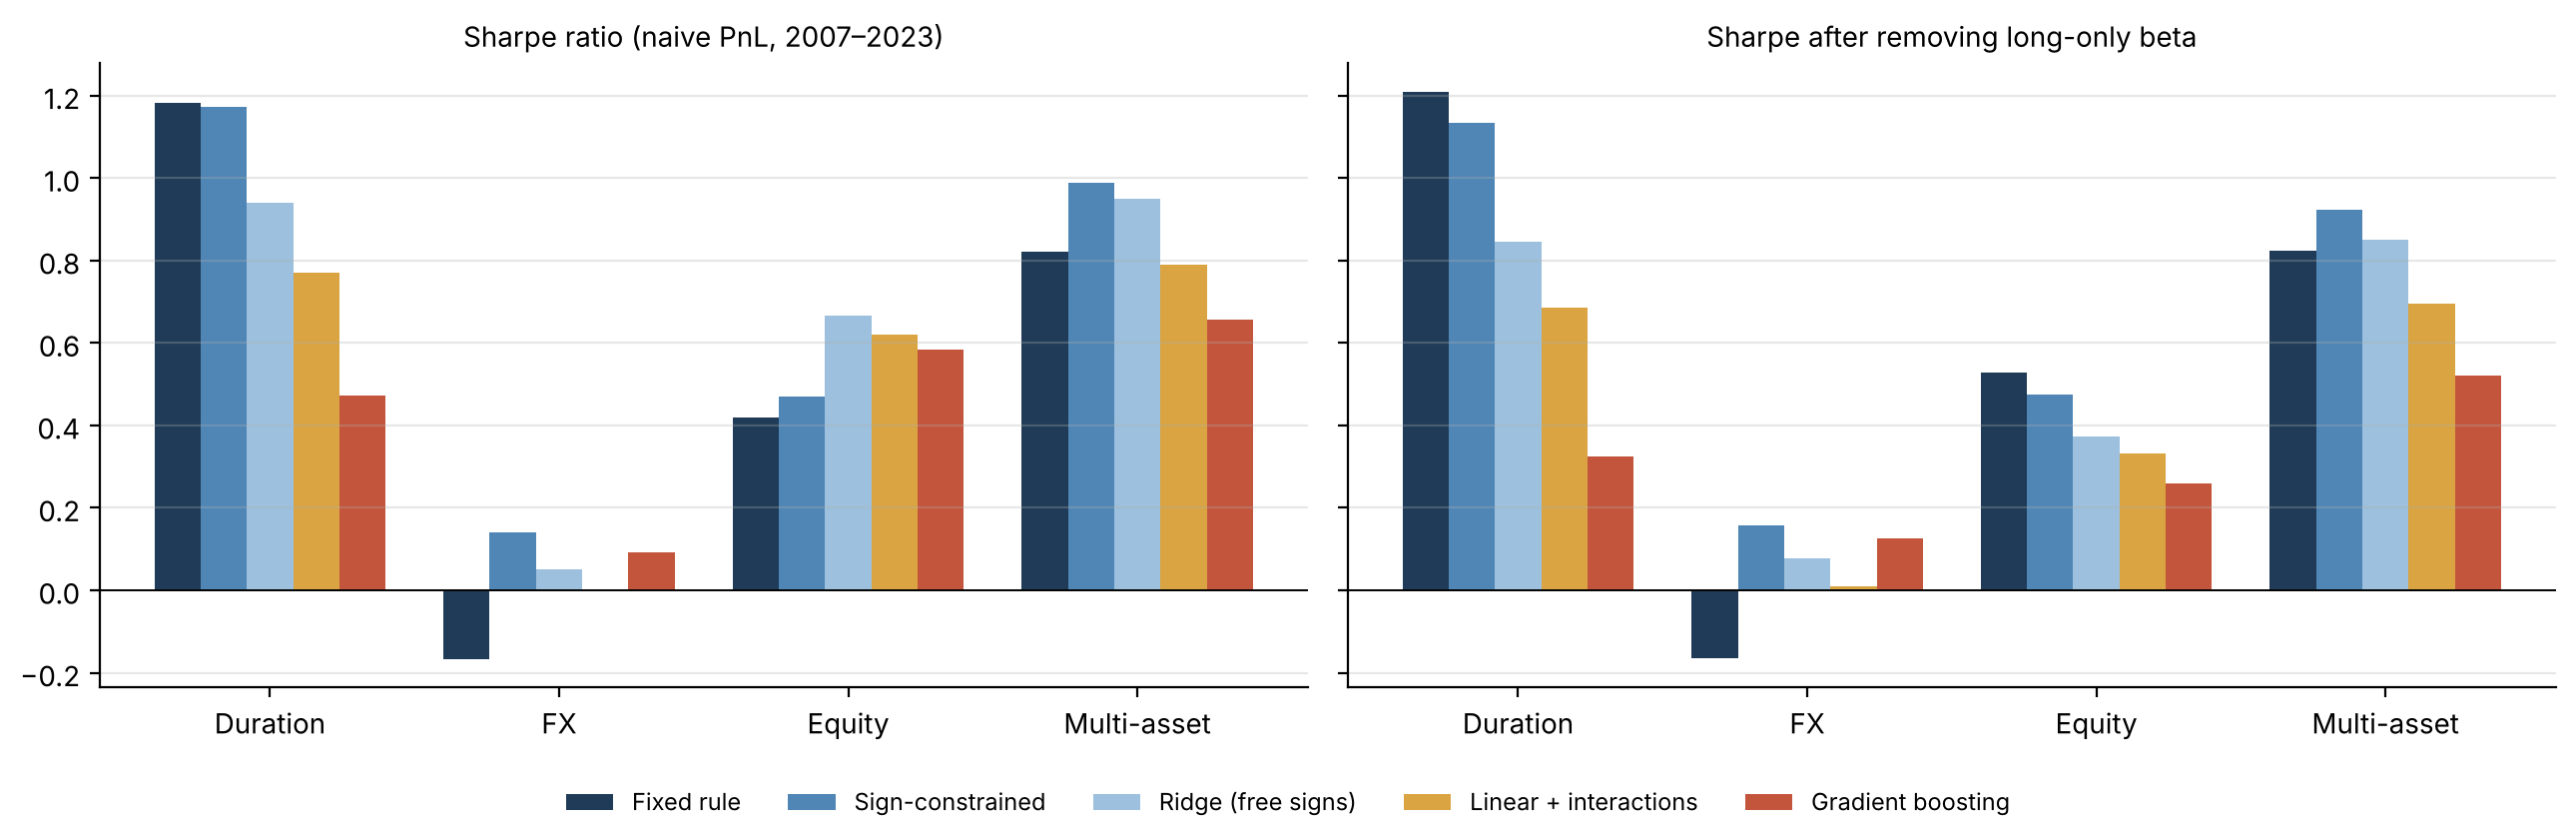

In [9]:
# ---- CELL B5: figure ----------------------------------------------------------
labels = {"RULE": "Fixed rule", "SIGNED": "Sign-constrained", "RIDGE": "Ridge (free signs)",
          "LIN_INT": "Linear + interactions", "GB": "Gradient boosting"}
colors = {"RULE": "#1f3b57", "SIGNED": "#4f86b5", "RIDGE": "#9cc0dd", "LIN_INT": "#d9a441", "GB": "#c4553d"}
groups = {**{a: evalB[a] for a in ASSETS}, "Multi-asset": evalPort}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for k, (col, title) in enumerate([("Sharpe", "Sharpe ratio (naive PnL, 2007–2023)"),
                                  ("beta-neutral Sharpe", "Sharpe after removing long-only beta")]):
    x = np.arange(len(groups))
    for i, s in enumerate(CANDS):
        vals = [groups[g].loc[s, col] for g in groups]
        ax[k].bar(x + (i - 2) * 0.16, vals, width=0.16, color=colors[s], label=labels[s])
    ax[k].set_xticks(x); ax[k].set_xticklabels(list(groups)); ax[k].axhline(0, color="k", lw=0.7)
    ax[k].set_title(title, fontsize=10); ax[k].grid(axis="y", alpha=0.3)
    for sp in ["top", "right"]:
        ax[k].spines[sp].set_visible(False)
fig.legend(*ax[0].get_legend_handles_labels(), fontsize=8.5, frameon=False, ncol=5, loc="lower center")
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig("partB_sharpe.png", dpi=150); plt.show()

### Part B · Results against the pre-registered criteria

**Verdict: no learner beats the fixed rules.** None of the 16 comparisons reaches the Bonferroni threshold
(t ≥ 2.96); the largest t-statistic against a rule is 1.51 (sign-constrained learner, FX).

| | Rule | Sign-constrained | Ridge (free signs) | Linear + interactions | Gradient boosting |
|---|---|---|---|---|---|
| **Duration**: IC / Sharpe / beta-neutral | 0.126 / **1.18** / **1.21** | 0.102 / 1.17 / 1.13 | 0.083 / 0.94 / 0.85 | 0.067 / 0.77 / 0.69 | 0.033 / 0.47 / 0.32 |
| **FX**: IC / Sharpe / beta-neutral | −0.003 / −0.17 / −0.17 | 0.008 / **0.14** / **0.16** | 0.001 / 0.05 / 0.08 | 0.013 / 0.00 / 0.01 | 0.012 / 0.09 / 0.13 |
| **Equity**: IC / Sharpe / beta-neutral | **0.085** / 0.42 / **0.53** | 0.061 / 0.47 / 0.47 | 0.047 / **0.67** / 0.37 | 0.046 / 0.62 / 0.33 | 0.038 / 0.58 / 0.26 |
| **Multi-asset**: Sharpe / beta-neutral | 0.82 / 0.82 | **0.99** / **0.92** | 0.95 / 0.85 | 0.79 / 0.70 | 0.66 / 0.52 |

*IC = pooled monthly Pearson correlation with next-month returns. Evaluation January 2007 – December 2023; naive
PnLs at 10% vol, monthly rebalancing, one-day slippage, gross of costs. Full tables, including HAC t-statistics
and developed/emerging sub-panel gaps, are in the cells above.*

**By asset class.**
1. **Duration (theory clear): the rule wins.** It has the highest IC and Sharpe. The sign-constrained learner
   ties it; every learner allowed to choose its own signs or discover interactions is worse, and gradient
   boosting is far worse. This is Part A's "rule exactly right" regime.
2. **FX (theory unclear): nothing predicts.** The rule's IC is −0.003 and the learners' are 0.001–0.013, none
   significant. The learners lead the rule by about 3% a year only because the rule loses money; none of them
   has a significant signal of its own. Machine learning cannot extract a signal the features do not contain.
3. **Equity: the learners' higher Sharpe is market beta, not skill.** Their PnLs correlate 0.64–0.71 with simply
   holding equities, because they learned to stay mostly long during a strong equity decade. Their ICs are all
   below the rule's, and after removing long-only beta the rule is best (0.53 against 0.26–0.47).
4. **Multi-asset portfolio.** The sign-constrained learner has the highest Sharpe (0.99 against 0.82), but the
   paired t-statistic is 0.76. Gradient boosting is last.

**Against the stated expectations.** (1) Duration: confirmed. (2) FX: the learners did come closest, but only
because the rule failed, not because they found a signal. (3) Equity: the rule turned out more predictive than
expected (IC 0.085); the learners were the weak ones. (4) No learner beats a rule: confirmed.

**Implementation notes, disclosed for completeness.** The first run left USD out of the three learners that use
FX carry, because USD (the base currency) has no carry series and its zero z-score was dropped. USD's carry was
set to zero by definition and everything re-run before these results were written. A beta-neutral Sharpe column
was added as a diagnostic; the decision rule was not changed.

## Conclusions: what limits machine learning against a fixed rule

**1. The answer depends on whether theory is right, and the simulations say how much.** When a theory-signed,
equal-weight rule matches the truth, no learner beats it at any panel size or signal strength. Learning pays only
when the rule is mis-specified in a way the learner can represent: unequal weights (sign-constrained regression)
or signs that flip by country or regime (linear models told which interaction to look for).

**2. Data volume is the binding constraint.** Even in the scenarios built for learning, the edge needs about 24
markets × 25 years at a realistic monthly R² of 2%, and then it is about +0.02 in IC. On 4 markets the rule wins
almost everywhere.

**3. Structure beats flexibility.** The learners that won in simulation were the most constrained ones: signs
fixed by theory, or a specified interaction. Gradient boosting, which must discover structure itself, was the
weakest learner both in simulation and on real data.

**4. On real JPMaQS data the predicted edge did not appear, and could not have been confirmed if it had.** No
learner passed the pre-registered test in any asset class or the multi-asset portfolio. An IC gain of 0.02 over
17 years is well inside sampling noise, so this result is what Part A predicts.

**5. Two traps that headline Sharpe ratios hide.** In FX the learners "beat" the rule only because the rule loses
money; none of their signals is significant. In equities the learners' higher Sharpe is mostly long-equity beta.
Comparing ICs, sub-panels and beta-neutral Sharpes exposes both.

**Practical rule.** Start with a theory-signed composite. Use a learner only to (a) re-weight inputs under sign
constraints, or (b) test a specific, economically motivated interaction, and judge it on out-of-sample IC,
sub-panel consistency and beta-neutral performance, not on headline Sharpe.

**Limits of this study.** Gross of transaction costs; one feature set per asset class; simulated features are
Gaussian AR(1) series with no structural breaks; only six simulated panels per cell; the Bonferroni threshold
makes the real-data test conservative.